# NCS / NCSE detection from an EDF+ EEG recording
**Modified Salzburg criteria, EEG-only branch** (the clinical-intervention part is ignored)

**What this notebook does**
1. Opens a long EDF+ recording (for example 24 hours) and reads it in pieces, so memory is never a problem.
2. Cleans the EEG, drops broken electrodes, and builds the leads you choose: **unipolar** (referential: every electrode exactly as stored in the file, the default) or the standard bipolar "double banana" montage.
3. Finds epileptiform discharges (ED): sharp spikes and sharp waves that stand out from the background.
4. Applies the Salzburg rules and tells you **when** it found
   * **NCS** (non-convulsive seizure): ED faster than 2.5 per second for at least 10 seconds, and
   * **NCSE** (non-convulsive status epilepticus): the same pattern for at least 10 minutes in a row, or for at least 20 % of any 60-minute period (12 minutes in total).
5. Saves tables, a report and pictures for expert review. **All times are given the way EDFbrowser shows them** (time since the start of the recording, and the clock time stored in the file header), so you can jump to each detection in EDFbrowser and check it there.

**How to use it:** edit the settings in Step 1, then use *Run All*. Every step has a short explanation above its code.

> **Important.** This is a research and screening aid, not a diagnostic tool. The detector thresholds are reasonable
> starting values, not tuned on labelled seizures. A clinical neurophysiologist must review every detection
> (see the excerpt pictures at the end).

## Step 0 - Import the tools
If a package is missing, remove the `#` in front of the `%pip` line and run the cell once.

In [14]:
# %pip install mne numpy scipy matplotlib

import os, re, json, warnings
from collections import Counter
from datetime import timedelta

import numpy as np
import matplotlib.pyplot as plt
import mne
from scipy.signal import butter, filtfilt, sosfiltfilt, iirnotch, find_peaks

mne.set_log_level("ERROR")                              # keep the output quiet
warnings.filterwarnings("ignore", category=RuntimeWarning)  # MNE warns about per-channel filter settings
%matplotlib inline

## Step 1 - Your settings (the only cell you normally need to edit)
* `EDF_PATH` - the EDF+ file. Use the EDF+ version because it carries the annotations (artifact marks).
  Tip: the file name may contain the patient's name; consider renaming a copy before you share this notebook.
* `MONTAGE` - `"referential"` (unipolar, the default) uses every good electrode exactly as stored in the file,
  which is what EDFbrowser shows when no montage is applied. `"bipolar"` subtracts neighbouring electrodes instead (the "double banana").
* **Times** follow EDFbrowser: *after start* = time since the start of the recording (EDFbrowser's relative display);
  *clock* = the start time stored in the file header plus that time (EDFbrowser's real-time display). No time-zone conversion is applied.
* `CHUNK_MIN` - how many minutes are processed at a time. 30 is a good value.
* `ARTIFACT_DEFAULT_S` - if an artifact annotation has no duration, assume it lasts this many seconds.

In [15]:
EDF_PATH = "edf_plus/MUFEED^MUFEED2.edf"      # <-- change this to your EDF+ file
OUT_DIR  = "ncs_out_24h"                 # results are saved here
MONTAGE  = "referential"                 # "referential" (unipolar, as recorded) or "bipolar"
CHUNK_MIN = 30                           # minutes processed per chunk
ARTIFACT_DEFAULT_S = 10.0                # used when an artifact annotation has zero duration

os.makedirs(OUT_DIR, exist_ok=True)

## Step 2 - The Salzburg rules (what we are looking for)
**ED - epileptiform discharge.** A short transient that stands out from the background and is one of:
a spike (shorter than 70 ms), a polyspike (several spikes in a burst), a sharp wave (70-200 ms),
a spike-and-slow-wave complex or a sharp-and-slow-wave complex. They can be focal, one-sided or generalised.

**How ED are counted.** In 10-second windows. "ED faster than 2.5 Hz" means **more than 25 ED in 10 s**
(exactly 25 does not count). A spike-and-slow-wave complex is **one** discharge, not two.

**NCS.** The ED > 2.5 Hz pattern lasts at least 10 s.

**NCSE.** The same pattern lasts at least 10 min without a break, **or** fills at least 20 % of any 60-minute period
(that is 12 minutes added up).

*References:* Beniczky et al., Epilepsia 2013 (original Salzburg criteria; please check its exact thresholds);
Leitinger et al., Lancet Neurology 2016, doi:10.1016/S1474-4422(16)30137-5 (diagnostic accuracy).

In [16]:
# ---- Salzburg criteria (EEG-only branch) ----
ED_RATE_HZ    = 2.5          # ED must be MORE than this many per second ...
RATE_WINDOW_S = 10.0         # ... counted in a 10-second window (so > 25 ED per 10 s)
NCS_MIN_S     = 10.0         # the pattern must last at least 10 s to be an NCS
NCSE_CONT_S   = 10 * 60.0    # NCSE rule (a): at least 10 minutes in a row
NCSE_FRAC     = 0.20         # NCSE rule (b): at least 20 % ...
NCSE_PERIOD_S = 60 * 60.0    #   ... of any 60-minute period (20 % of 60 min = 12 min)
MERGE_GAP_S   = 2.0          # a pause shorter than this does not break a pattern into two

## Step 3 - Detector settings (how discharges are found)
These are starting values. Change them only if you can compare the result with an expert's markings.
* **Channels / montage.** Only scalp electrodes are used (ear and ECG channels are ignored). With `MONTAGE = "referential"`
  (unipolar, the default) every good electrode is used exactly as stored in the file - the same traces EDFbrowser shows
  without a montage. With `"bipolar"`, neighbouring electrodes are subtracted from each other (the "double banana").
* **Prominence.** A discharge must rise at least `MIN_PROM_UV` microvolts above its surroundings **and** at least
  `K_SIGMA` times the normal background noise of that lead.
* **Width.** Between 20 and 200 ms (spikes and sharp waves). Slower blinks and drifts are too wide; very narrow clicks are too thin.
* **Seen on several leads.** A real discharge has a field. Unipolar: it must appear in at least 3 channels within 200 ms
  (one noisy electrode only affects its own channel). Bipolar: at least 2 leads that involve at least 2 electrodes
  (one noisy electrode shows up in two neighbouring leads that share it).
* **Reference artifact.** In unipolar view, activity at the *reference* electrode appears in every channel at once. If a
  detection looks suspiciously identical in all channels, check it in EDFbrowser with a different reference.

In [17]:
# ---- signal cleaning ----
NOTCH_HZ    = 50.0           # mains frequency (50 Hz in India/Europe, use 60 for the US)
BAND_HZ     = (1.0, 35.0)    # band-pass used for discharge detection
EMG_BAND_HZ = (20.0, 35.0)   # band where muscle artifact shows up

# ---- electrodes and montage ----
SCALP = ["Fp1","Fp2","F7","F3","Fz","F4","F8","T3","C3","Cz","C4",
         "T4","T5","P3","Pz","P4","T6","O1","O2"]          # A1/A2 (ears) are not used
BIPOLAR = [("Fp1","F7"),("F7","T3"),("T3","T5"),("T5","O1"),   # left temporal chain
           ("Fp2","F8"),("F8","T4"),("T4","T6"),("T6","O2"),   # right temporal chain
           ("Fp1","F3"),("F3","C3"),("C3","P3"),("P3","O1"),   # left parasagittal
           ("Fp2","F4"),("F4","C4"),("C4","P4"),("P4","O2"),   # right parasagittal
           ("Fz","Cz"),("Cz","Pz")]                            # midline
# extra electrodes that exist in your file; they are read only so their quality can be judged
CANDIDATE_EEG = SCALP + ["FC5","FC1","FC2","FC6","AF3","AF4","CP1","CP2","CP5","CP6","PO3","PO4","Oz"]

# ---- bad channel handling ----
BAD_RATIO       = 3.0    # channel much noisier than the others -> bad
FLAT_RATIO      = 0.1    # channel almost flat -> bad
MIN_DERIVATIONS = 6      # a chunk with fewer usable leads is reported as "not evaluable"
CHUNK_BAD_RATIO  = 10.0  # electrode that jumps > 10x its normal level during the recording -> failed
CHUNK_FLAT_RATIO = 0.05  # (deliberately lenient: a seizure makes good channels larger, not broken)

# ---- calibration and chunking ----
CAL_N     = 60           # number of one-minute samples used to learn normal noise levels
CAL_LEN_S = 60
PAD_S     = 10.0         # extra seconds read around each chunk to avoid filter edge effects

# ---- discharge detector ----
MIN_PROM_UV = 50.0       # smallest peak prominence in a bipolar lead (microvolts)
K_SIGMA     = 4.0        # ... and at least this many times the background noise
ED_WIDTH_S  = (0.020, 0.200)   # spike < 70 ms, sharp wave 70-200 ms
ARTIFACT_UV = 600.0      # a deflection larger than this is an artifact, not a discharge
ED_MAX_S    = 0.200      # peaks within 200 ms (even in different leads) are ONE discharge
MIN_CHANNELS = 3 if MONTAGE == "referential" else 2   # leads a discharge must appear in (within 200 ms)
REQUIRE_MULTI_ELECTRODE = True   # reject events explained by a single electrode (noise)
EMG_RATIO   = 6.0        # muscle artifact if 20-35 Hz energy is this many times the quiet level ...
EMG_SHAPE_RATIO = 4.0    # ... AND 20-35 Hz energy compared with 1-20 Hz energy is this many times the quiet level
                         # (spike trains carry plenty of 1-20 Hz energy too, muscle does not - this keeps real seizures from being masked)
EMG_PAD_S   = 2          # also ignore this many seconds around muscle artifact

## Step 4 - Cleaning the signal
Two small building blocks:
* `preprocess` removes mains hum (50 Hz notch) and keeps 1-35 Hz. It filters forwards and backwards so that spikes are not shifted in time.
* `epoch_sigma` measures how big the "normal" background is in every 10-second piece, using a robust statistic
  (the median absolute deviation) that is not fooled by a few big spikes.

In [18]:
def preprocess(data, fs):
    """Notch out mains hum, then band-pass 1-35 Hz (zero-phase, so timing is not shifted)."""
    b, a = iirnotch(NOTCH_HZ, Q=30.0, fs=fs)
    x = filtfilt(b, a, data, axis=-1)
    sos = butter(4, BAND_HZ, btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=-1)


def epoch_sigma(x, fs, win_s=10.0):
    """Robust noise level (MAD-based sigma) for every non-overlapping 10-s piece.
    Returns an array shaped (..., number_of_pieces)."""
    n = int(win_s * fs)
    k = x.shape[-1] // n
    e = x[..., : k * n].reshape(*x.shape[:-1], k, n)
    med = np.median(e, axis=-1, keepdims=True)
    return 1.4826 * np.median(np.abs(e - med), axis=-1)

## Step 5 - Judging the electrodes and choosing the leads (montage)
* `find_bad_channels` compares every channel with the others. A channel that is far too noisy (or flat) is dropped.
  It uses the **quiet-state** level (the 25th percentile over time), so a long seizure that makes many channels
  large cannot hide a genuinely noisy electrode.
* `build_referential` (**unipolar**) keeps every good scalp electrode exactly as stored in the file, ordered front to back,
  left and right side by side.
* `build_bipolar` subtracts neighbouring electrodes (for example Fp1-F7). A lead is skipped if either electrode is bad.
* `build_leads` picks one of the two according to `MONTAGE`; the rest of the notebook only calls `build_leads`.

In [19]:
def find_bad_channels(x, names, fs):
    """Return (set of bad channel names, {channel: quiet-state amplitude}, reference level)."""
    amp = np.percentile(epoch_sigma(x, fs), 25, axis=-1)      # quiet-state amplitude per channel
    ref = np.median(amp)                                       # typical channel
    bad = {n for n, a in zip(names, amp)
           if a > BAD_RATIO * ref or a < FLAT_RATIO * ref}
    return bad, dict(zip(names, amp)), ref


def build_bipolar(x, names, bad):
    """Subtract neighbouring electrodes; skip any pair that contains a bad electrode."""
    idx = {n: i for i, n in enumerate(names)}
    labels, rows = [], []
    for a, b in BIPOLAR:
        if a in idx and b in idx and a not in bad and b not in bad:
            labels.append(f"{a}-{b}")
            rows.append(x[idx[a]] - x[idx[b]])
    return labels, np.array(rows)


# order in which unipolar channels are listed and drawn (left side, then right side, front to back)
DISPLAY_ORDER = ["Fp1","F7","F3","FC5","T3","C3","T5","P3","O1",
                 "Fz","FC2","Cz","Pz",
                 "Fp2","F8","F4","T4","C4","T6","P4","O2"]

def build_referential(x, names, bad):
    """UNIPOLAR: every good scalp electrode as stored in the file (no subtraction)."""
    idx = {n: i for i, n in enumerate(names)}
    good = [n for n in names if n not in bad]
    labels = [n for n in DISPLAY_ORDER if n in good] + [n for n in good if n not in DISPLAY_ORDER]
    return labels, np.array([x[idx[n]] for n in labels])


def build_leads(x, names, bad):
    """The leads used for detection, chosen by MONTAGE ("referential" or "bipolar")."""
    if MONTAGE == "referential":
        return build_referential(x, names, bad)
    if MONTAGE == "bipolar":
        return build_bipolar(x, names, bad)
    raise ValueError('MONTAGE must be "referential" or "bipolar"')

## Step 6 - Muscle artifact
Chewing, frowning and similar movements create fast, messy activity (20-35 Hz) in most leads at once.
`emg_per_second` measures that activity every second; `emg_mask` marks seconds where it is more than `EMG_RATIO`
times the quiet level. Discharges found in marked seconds are ignored.

To avoid mistaking a real spike train for muscle, a second is marked only if the fast activity is **also large compared with
the slower 1-20 Hz activity** (`EMG_SHAPE_RATIO`). Muscle is mostly fast; spikes and slow waves bring a lot of slower energy too.

The quiet level is taken from the quietest 5 % of seconds, so a very long seizure cannot raise its own bar.

In [20]:
def emg_per_second(leads, fs):
    """For every second: fast activity (20-35 Hz RMS) and slower activity (1-20 Hz RMS),
    each taken as the median across leads. Returns (fast, slow)."""
    def per_second_rms(band):
        sos = butter(4, band, btype="bandpass", fs=fs, output="sos")
        h = sosfiltfilt(sos, leads, axis=-1)
        n = int(fs)
        k = h.shape[-1] // n
        rms = np.sqrt((h[:, : k * n].reshape(leads.shape[0], k, n) ** 2).mean(-1))
        return np.median(rms, axis=0)
    return per_second_rms(EMG_BAND_HZ), per_second_rms((BAND_HZ[0], EMG_BAND_HZ[0]))


def emg_mask(leads, fs, base=None):
    """True for every second that looks like muscle artifact.
    base = (quiet fast level, quiet fast/slow ratio); chunked runs pass recording-wide values."""
    fast, slow = emg_per_second(leads, fs)
    shape = fast / (slow + 1e-9)                         # how 'fast-dominated' each second is
    if base is None:
        base = (np.percentile(fast, 5) + 1e-9, np.percentile(shape, 5) + 1e-9)
    hit = (fast / base[0] > EMG_RATIO) & (shape / base[1] > EMG_SHAPE_RATIO)
    pad = np.ones(2 * EMG_PAD_S + 1)                     # also cover the seconds around a hit
    return np.convolve(hit.astype(float), pad, mode="same") > 0

## Step 7 - Finding epileptiform discharges (ED)
Two stages:

**7a. Candidates in one lead.** `find_peaks` looks for sharp peaks of either polarity that are tall enough
(prominence) and have a spike-or-sharp-wave width (20-200 ms).
The height threshold is the larger of a fixed value (`MIN_PROM_UV`) and `K_SIGMA` times that lead's normal noise.

In [21]:
def detect_candidates(sig, fs, sigma_bg=None):
    """Times (s) of sharp transients in ONE bipolar lead.
    sigma_bg = normal background noise of the lead; if not given, the quietest quartile of `sig` is used."""
    if sigma_bg is None:
        sigma_bg = np.percentile(epoch_sigma(sig, fs), 25)
    prom = max(MIN_PROM_UV, K_SIGMA * sigma_bg)               # how tall a peak must be
    width = (ED_WIDTH_S[0] * fs, ED_WIDTH_S[1] * fs)           # allowed width in samples
    times = []
    for sign in (1.0, -1.0):                                   # look for up- and down-going peaks
        pk, _ = find_peaks(sign * sig, prominence=prom, width=width,
                           rel_height=0.5, distance=max(1, int(0.06 * fs)))
        pk = pk[np.abs(sig[pk]) < ARTIFACT_UV]                 # throw away huge artifacts
        times.append(pk / fs)
    return np.sort(np.concatenate(times)), prom

**7b. From peaks to discharges.** The same discharge usually appears in several leads at nearly the same moment.
We group peaks that fall within 200 ms (the longest a single discharge lasts) into **one discharge**, so a
spike-and-slow-wave complex is counted once.
A group is kept only if it was seen in at least `MIN_CHANNELS` leads (3 unipolar, 2 bipolar), if - for bipolar leads - it involves at least
two electrodes (otherwise it is probably one noisy electrode), and if it is not inside a muscle-artifact second.

In [22]:
def detect_discharges(bip, labels, fs, masked_seconds, sigma_bg=None):
    """Group candidate peaks from all leads into discharges.
    Returns: event times (s), the lead indices of each event, and the height thresholds used."""
    cand, thresholds = [], {}
    for i, lab in enumerate(labels):
        t, thresholds[lab] = detect_candidates(
            bip[i], fs, None if sigma_bg is None else sigma_bg[lab])
        cand += [(tt, i) for tt in t]                           # (time, lead number)
    cand.sort()

    events, chans = [], []
    j = 0
    while j < len(cand):
        t0 = cand[j][0]
        group = []
        while j < len(cand) and cand[j][0] - t0 <= ED_MAX_S:    # everything within 200 ms = one discharge
            group.append(cand[j]); j += 1
        leads = sorted({c for _, c in group})
        sec = int(np.median([t for t, _ in group]))
        in_muscle = sec < len(masked_seconds) and masked_seconds[sec]
        # a single noisy electrode appears in every lead that contains it:
        one_electrode = bool(set.intersection(*[set(labels[c].split("-")) for c in leads]))
        if REQUIRE_MULTI_ELECTRODE and one_electrode:
            continue
        if len(leads) >= MIN_CHANNELS and not in_muscle:
            events.append(float(np.median([t for t, _ in group])))
            chans.append(leads)
    return np.array(events), chans, thresholds

## Step 8 - Applying the Salzburg rules to the discharge times
**8a. Where is the pattern?** `window_counts` slides a 10-second window along the recording in 1-second steps and
counts discharges in each. A window is *positive* if it holds **more than 25** discharges (> 2.5 per second).
`find_segments` joins neighbouring positive windows into runs (a pause of up to `MERGE_GAP_S` seconds does not split a run),
trims each run to its first and last discharge, and marks it as **NCS** if it lasts at least 10 seconds.

In [23]:
def window_counts(events, total_s, step_s=1.0):
    """For each 10-s window (moved in 1-s steps): how many discharges does it contain?"""
    last = max(total_s - RATE_WINDOW_S, 0.0)
    starts = np.arange(0.0, last + 1e-9, step_s)
    lo = np.searchsorted(events, starts, side="left")
    hi = np.searchsorted(events, starts + RATE_WINDOW_S, side="left")
    return starts, hi - lo


def find_segments(events, total_s):
    """Runs of windows with > 2.5 discharges/s, trimmed to first/last discharge."""
    starts, counts = window_counts(events, total_s)
    positive = counts > ED_RATE_HZ * RATE_WINDOW_S               # strictly more than 25
    runs = []
    for s, p in zip(starts, positive):
        if not p:
            continue
        a, b = s, s + RATE_WINDOW_S
        if runs and a <= runs[-1][1] + MERGE_GAP_S:              # continues the previous run
            runs[-1][1] = max(runs[-1][1], b)
        else:
            runs.append([a, b])
    segs = []
    for a, b in runs:
        ev = events[(events >= a) & (events < b)]
        start, end = float(ev[0]), float(ev[-1])
        dur = end - start
        segs.append({"start_s": start, "end_s": end, "duration_s": dur,
                     "n_discharges": int(len(ev)),
                     "mean_rate_hz": (len(ev) - 1) / dur if dur > 0 else 0.0,
                     "is_ncs": bool(dur >= NCS_MIN_S)})           # the 10-second rule
    return segs, starts, counts

**8b. When did NCSE begin?** `ncse_timeline` checks the two NCSE rules and returns the **time** each one was reached:
* *Continuous:* one NCS run of at least 10 minutes. The criterion is reached 10 minutes after the run begins.
* *Cumulative:* the first moment when the NCS time inside the preceding 60 minutes adds up to 12 minutes.

In [24]:
def ncse_timeline(segs, total_s):
    ncs = [s for s in segs if s["is_ncs"]]
    out = {"continuous": None, "cumulative": None}

    # rule (a): a single run of >= 10 minutes
    for s in ncs:
        if s["duration_s"] >= NCSE_CONT_S:
            out["continuous"] = {"pattern_start_s": s["start_s"],
                                 "criterion_met_s": s["start_s"] + NCSE_CONT_S,
                                 "pattern_end_s": s["end_s"]}
            break

    # rule (b): >= 12 min of NCS inside any 60-minute window.
    on = np.zeros(int(np.ceil(total_s)) + 1)                     # 1 for every second that is inside an NCS
    for s in ncs:
        on[int(s["start_s"]): int(np.ceil(s["end_s"]))] = 1
    cs = np.concatenate([[0.0], np.cumsum(on)])
    t = np.arange(len(cs))
    W = int(NCSE_PERIOD_S)
    in_last_hour = cs[t] - cs[np.maximum(t - W, 0)]              # NCS seconds in the hour ending at t
    hit = np.where(in_last_hour >= NCSE_FRAC * NCSE_PERIOD_S)[0]
    if len(hit):
        te = int(hit[0])                                         # first moment the 12 minutes are reached
        w0 = max(te - W, 0)
        first = next(s for s in ncs if s["end_s"] > w0 and s["start_s"] < te)
        out["cumulative"] = {"pattern_start_s": first["start_s"],
                             "criterion_met_s": float(te),
                             "ncs_time_s": float(in_last_hour[te])}
    return out


def hms(t):
    """Seconds -> H:MM:SS.s (one decimal, like the time axis in EDFbrowser)."""
    t = round(float(t), 1)                       # round first so 59.96 becomes 1:00.0, not 0:60.0
    h, rem = divmod(t, 3600)
    m, s = divmod(rem, 60)
    return f"{int(h)}:{int(m):02d}:{s:04.1f}"

### Quick self-test of the rules (no EEG needed)
These checks feed made-up discharge times into the rules above and confirm the answers. If one of them fails,
the rules were changed by mistake.

In [25]:
train = lambda t0, t1, hz: list(np.arange(t0, t1, 1 / hz))       # evenly spaced discharges

def run(times, total):
    segs, _, _ = find_segments(np.sort(np.array(times)), total)
    return segs, ncse_timeline(segs, total)

segs, _ = run(train(100, 160, 2.5), 400)
assert len(segs) == 0, "exactly 2.5 Hz must NOT count (needs MORE than 25 per 10 s)"

segs, _ = run(train(100, 160, 2.6), 400)
assert len(segs) == 1 and segs[0]["is_ncs"], "2.6 Hz for 60 s must be an NCS"

segs, _ = run(train(100, 109, 3.0), 400)
assert not any(s["is_ncs"] for s in segs), "9 s of 3 Hz is too short for an NCS"

segs, _ = run(train(100, 120, 3) + train(121.5, 140, 3), 400)
assert len(segs) == 1, "a 1.5 s pause must not split the pattern"

segs, _ = run(train(100, 120, 3) + train(130, 150, 3), 400)
assert len(segs) == 2, "a 10 s pause must split the pattern"

_, tl = run(train(100, 702, 3.0), 1200)
assert tl["continuous"] is not None, "10 minutes of 3 Hz must be NCSE"

_, tl = run(train(100, 690, 3.0), 1200)
assert tl["continuous"] is None, "9.8 minutes must not be NCSE (continuous rule)"

def pulses(k):                                                    # k runs of 1 minute, 2 minutes apart
    t = []
    for i in range(k):
        t += train(60 + i * 180, 120 + i * 180, 3.0)
    return t
_, tl = run(pulses(13), 3600)
assert tl["cumulative"] is not None, "13 x 1 min inside 60 min (>= 12 min) must be NCSE"
_, tl = run(pulses(11), 3600)
assert tl["cumulative"] is None, "11 x 1 min (< 12 min) must not be NCSE"
print("All rule checks passed.")

All rule checks passed.


## Step 9 - Open the EDF+ file
`preload=False` means the signal is **not** loaded into memory yet; we read it in pieces later.
We print only technical facts. The patient's name and ID stored in the file header are deliberately **not** printed.

`pick_eeg` finds the usable scalp channels even if they are called "EEG Fp1", "Fp1-REF" or just "Fp1".
`read_uv` reads a time span and converts volts to microvolts.

In [26]:
raw = mne.io.read_raw_edf(EDF_PATH, preload=False, verbose=False)
fs = float(raw.info["sfreq"])                    # samples per second
total_s = raw.n_times / fs                       # recording length in seconds

# TIME SETTINGS - the same as EDFbrowser.
# An EDF file stores its start time as plain local wall-clock time with NO time zone. MNE attaches the label "UTC" to it,
# but that label is only a placeholder, so we remove it and use the start time exactly as written in the header.
# This is the start time EDFbrowser shows in its real-time display; NO time-zone conversion is applied.
meas = raw.info["meas_date"]
start_dt = meas.replace(tzinfo=None) if meas is not None else None

def clock(t):
    """Seconds after the start of the recording -> clock time text 'YYYY-MM-DD HH:MM:SS.s' (header start + t)."""
    if start_dt is None:
        return ""
    dt = start_dt + timedelta(seconds=round(float(t), 1))
    return dt.strftime("%Y-%m-%d %H:%M:%S") + f".{dt.microsecond // 100000}"

def when(t):
    """Readable 'when' text: time after the start of the recording, plus the clock time."""
    c = clock(t)
    return f"{hms(t)} after start" + (f" (clock {c})" if c else "")


def pick_eeg(raw):
    """{clean 10-20 name: name used in the file} for usable scalp channels."""
    mapping = {}
    for c in raw.ch_names:
        n = re.sub(r"^EEG\s+", "", c.strip(), flags=re.I)         # drop a leading "EEG "
        n = re.sub(r"-(REF|LE|AR)$", "", n, flags=re.I)           # drop a trailing "-REF"
        if n in CANDIDATE_EEG:
            mapping[n] = c
    return mapping

def read_uv(t0, t1):
    """Read seconds [t0, t1) of the scalp channels, in microvolts. Returns (data, channel names)."""
    names = list(mapping)
    i0, i1 = int(round(t0 * fs)), int(round(t1 * fs))
    d = raw.get_data(picks=[mapping[n] for n in names], start=i0, stop=i1)
    return d * 1e6, names

mapping = pick_eeg(raw)
print(f"Recording length : {total_s/3600:.2f} h  ({total_s:.0f} s)")
print(f"Sampling rate    : {fs:g} Hz")
print(f"Start time       : {clock(0) or 'unknown'}  (taken from the file header, as EDFbrowser shows it)")
print(f"Montage          : {MONTAGE}")
print(f"Scalp channels used ({len(mapping)}): {list(mapping)}")
assert len(mapping) >= 10, "Too few usable EEG channels were recognised - check the channel names above."

Recording length : 24.15 h  (86934 s)
Sampling rate    : 128 Hz
Start time       : 2024-02-01 11:47:33.0  (taken from the file header, as EDFbrowser shows it)
Montage          : referential
Scalp channels used (32): ['FC5', 'AF3', 'Fp1', 'Fp2', 'AF4', 'FC6', 'FC1', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC2', 'T3', 'C3', 'Cz', 'C4', 'T4', 'CP1', 'T5', 'P3', 'Pz', 'P4', 'T6', 'CP2', 'CP5', 'PO3', 'O1', 'Oz', 'O2', 'PO4', 'CP6']


### The annotations stored in the EDF+ file
EDF+ files can contain text marks with a start time. Marks that contain the word **"artifact"** are used later to
ignore those periods. Other marks (for example "slowing") are only listed here for your information.

In [27]:
t_first = getattr(raw, "first_time", 0.0)
ann = raw.annotations
print(f"{len(ann)} annotation(s)")
for on, du, tx in list(zip(ann.onset, ann.duration, ann.description))[:60]:
    print(f"  {hms(on - t_first)}  ({(on - t_first)/3600:5.2f} h)  duration {du:6.1f} s   {tx}")

10 annotation(s)
  4:59:46.8  ( 5.00 h)  duration    0.0 s   slowing
  5:32:52.8  ( 5.55 h)  duration    0.0 s   ecg artifact
  9:15:21.4  ( 9.26 h)  duration    0.0 s   slowing
  10:58:18.2  (10.97 h)  duration    0.0 s   artifact
  11:36:57.1  (11.62 h)  duration    0.0 s   slowing
  13:25:25.6  (13.42 h)  duration    0.0 s   moment artifact
  16:09:07.3  (16.15 h)  duration    0.0 s   slowing
  19:31:18.7  (19.52 h)  duration    0.0 s   moment artifact
  22:07:35.3  (22.13 h)  duration    0.0 s   electord artifact
  22:09:27.0  (22.16 h)  duration    0.0 s   artifact


## Step 10 - Calibration: learn what "normal" looks like in this recording
A 24-hour recording changes over time, and a seizure can fill hours. If we measured "normal" inside each chunk,
a long seizure would look normal. So we take **60 one-minute samples spread evenly over the whole recording** and learn from them:
* which electrodes are bad,
* the normal background noise of every lead (for the height threshold),
* the quiet level of muscle activity.

In [28]:
def calibrate():
    n = int(min(CAL_N, total_s // CAL_LEN_S))
    assert n >= 3, "Recording is too short for calibration (needs at least 3 minutes)."
    starts = np.linspace(0, total_s - CAL_LEN_S, n)             # evenly spread samples
    pieces = []
    for s in starts:
        d, names = read_uv(s, s + CAL_LEN_S)
        pieces.append(preprocess(d, fs))

    # 1) bad electrodes, judged on all samples together
    bad, amp, _ = find_bad_channels(np.concatenate(pieces, axis=1), names, fs)

    # 2) normal noise per lead and quiet muscle level
    sig, fast_all, shape_all = {}, [], []
    for x in pieces:
        labels, leads = build_leads(x, names, bad)
        for lab, e in zip(labels, epoch_sigma(leads, fs)):
            sig.setdefault(lab, []).append(e)
        fast, slow = emg_per_second(leads, fs)
        fast_all.append(fast); shape_all.append(fast / (slow + 1e-9))
    return {"bad": bad,                                         # bad electrodes
            "amp": amp,                                         # normal amplitude of each channel
            "sigma_bg": {k: float(np.percentile(np.concatenate(v), 25)) for k, v in sig.items()},
            # quiet level of fast activity, and quiet fast/slow ratio (muscle check)
            "emg_base": (float(np.percentile(np.concatenate(fast_all), 5)) + 1e-9,
                         float(np.percentile(np.concatenate(shape_all), 5)) + 1e-9)}

cal = calibrate()
print("Bad electrodes excluded:", sorted(cal["bad"]) or "none")
print("Leads available:", len(cal["sigma_bg"]), "-", ", ".join(cal["sigma_bg"]))

Bad electrodes excluded: ['AF3', 'AF4', 'CP1', 'CP2', 'CP5', 'CP6', 'FC1', 'FC6', 'Oz', 'PO3', 'PO4']
Leads available: 21 - Fp1, F7, F3, FC5, T3, C3, T5, P3, O1, Fz, FC2, Cz, Pz, Fp2, F8, F4, T4, C4, T6, P4, O2


## Step 11 - Process the recording chunk by chunk
For every chunk (default 30 minutes) we: read it with 10 s of padding, clean it, drop any electrode that failed
during this chunk, build the leads, mask muscle artifact, and detect discharges.
Only discharges inside the chunk itself are kept (the padding belongs to the neighbouring chunk), so nothing is counted twice.

If too few leads remain in a chunk, it is reported as **not evaluable** instead of being silently treated as "normal".

In [29]:
def process_chunk(c0, c1):
    r0, r1 = max(c0 - PAD_S, 0.0), min(c1 + PAD_S, total_s)       # read with padding
    d, names = read_uv(r0, r1)
    x = preprocess(d, fs)

    # did an electrode fail during this chunk? (lenient on purpose - seizures make good channels bigger)
    amp = np.percentile(epoch_sigma(x, fs), 25, axis=-1)
    bad = set(cal["bad"])
    for n, a in zip(names, amp):
        if a > CHUNK_BAD_RATIO * cal["amp"][n] or a < CHUNK_FLAT_RATIO * cal["amp"][n]:
            bad.add(n)

    labels, leads = build_leads(x, names, bad)
    if len(labels) < MIN_DERIVATIONS:
        return None                                               # not evaluable

    mask = emg_mask(leads, fs, base=cal["emg_base"])
    ev, ch, _ = detect_discharges(leads, labels, fs, mask, sigma_bg=cal["sigma_bg"])
    t = ev + r0                                                    # back to time since recording start
    keep = (t >= c0) & (t < c1)                                    # discard the padding region
    return {"t": t[keep],
            "labels": [[labels[i] for i in c] for c, k in zip(ch, keep) if k],
            "masked_s": int(mask[int(c0 - r0): int(c1 - r0)].sum()),
            "n_leads": len(labels)}

In [30]:
# split the recording into chunks (a very short last piece is merged into the one before it)
step = CHUNK_MIN * 60
edges = list(np.arange(0, total_s, step)) + [total_s]
if len(edges) > 2 and edges[-1] - edges[-2] < 120:
    edges.pop(-2)
chunks = list(zip(edges[:-1], edges[1:]))

ev_all, lab_all, not_evaluable, masked_total = [], [], [], 0
for i, (c0, c1) in enumerate(chunks, 1):
    r = process_chunk(c0, c1)
    if r is None:
        not_evaluable.append((c0, c1))
        print(f"chunk {i:3d}/{len(chunks)}  {hms(c0)}-{hms(c1)}  NOT EVALUABLE (too many bad channels)", flush=True)
        continue
    ev_all.append(r["t"]); lab_all += r["labels"]; masked_total += r["masked_s"]
    print(f"chunk {i:3d}/{len(chunks)}  {hms(c0)}-{hms(c1)}  {len(r['t']):5d} discharges, {r['n_leads']} leads", flush=True)

events = np.concatenate(ev_all) if ev_all else np.array([])
order = np.argsort(events)                                         # sort everything by time
events = events[order]
lab_all = [lab_all[j] for j in order]
print(f"\nTotal discharges: {len(events)};  seconds masked as muscle artifact: {masked_total}")

chunk   1/49  0:00:00.0-0:30:00.0     38 discharges, 21 leads
chunk   2/49  0:30:00.0-1:00:00.0     15 discharges, 21 leads
chunk   3/49  1:00:00.0-1:30:00.0     65 discharges, 21 leads
chunk   4/49  1:30:00.0-2:00:00.0     17 discharges, 21 leads
chunk   5/49  2:00:00.0-2:30:00.0     33 discharges, 21 leads
chunk   6/49  2:30:00.0-3:00:00.0     26 discharges, 21 leads
chunk   7/49  3:00:00.0-3:30:00.0     31 discharges, 21 leads
chunk   8/49  3:30:00.0-4:00:00.0     25 discharges, 21 leads
chunk   9/49  4:00:00.0-4:30:00.0     15 discharges, 21 leads
chunk  10/49  4:30:00.0-5:00:00.0     25 discharges, 21 leads
chunk  11/49  5:00:00.0-5:30:00.0     43 discharges, 21 leads
chunk  12/49  5:30:00.0-6:00:00.0     43 discharges, 21 leads
chunk  13/49  6:00:00.0-6:30:00.0    162 discharges, 21 leads
chunk  14/49  6:30:00.0-7:00:00.0     99 discharges, 21 leads
chunk  15/49  7:00:00.0-7:30:00.0    284 discharges, 21 leads
chunk  16/49  7:30:00.0-8:00:00.0    200 discharges, 21 leads
chunk  1

## Step 12 - Ignore periods marked as artifact in the EDF+ annotations
Any annotation whose text contains "artifact" (this also catches spellings such as "moment artifact") is treated as
a bad period. Discharges inside it are removed. If an annotation has no duration, `ARTIFACT_DEFAULT_S` seconds are used.

In [31]:
bad_periods = []
for on, du, tx in zip(ann.onset, ann.duration, ann.description):
    if "artifact" in tx.lower() or "artefact" in tx.lower():
        a = float(on) - t_first
        bad_periods.append((a, a + (float(du) if du > 0 else ARTIFACT_DEFAULT_S), tx))

n_before = len(events)
if bad_periods and len(events):
    keep = np.ones(len(events), bool)
    for a, b, _ in bad_periods:
        keep &= ~((events >= a) & (events < b))
    events = events[keep]
    lab_all = [l for l, k in zip(lab_all, keep) if k]
print(f"{len(bad_periods)} annotated artifact period(s); removed {n_before - len(events)} discharge(s); {len(events)} remain.")

6 annotated artifact period(s); removed 17 discharge(s); 4927 remain.


## Step 13 - Apply the Salzburg rules to the whole recording
Now the rules of Step 8 are applied to the full list of discharge times.
For every run we also list the four leads that carried the most discharges, which hints at where the activity is.

In [32]:
segs, starts, counts = find_segments(events, total_s)

for s in segs:                                                     # which leads carry the discharges?
    tally = Counter(l for e, ls in zip(events, lab_all)
                    if s["start_s"] <= e <= s["end_s"] for l in ls)
    s["top_leads"] = [k for k, _ in tally.most_common(4)]

ncs = [s for s in segs if s["is_ncs"]]
timeline = ncse_timeline(segs, total_s)
max_count = int(counts.max()) if len(counts) else 0
print(f"Runs with > 2.5 discharges/s: {len(segs)}   of which NCS (>= 10 s): {len(ncs)}")
print(f"Most discharges in any 10-s window: {max_count}  (rule: more than {int(ED_RATE_HZ * RATE_WINDOW_S)})")

Runs with > 2.5 discharges/s: 7   of which NCS (>= 10 s): 4
Most discharges in any 10-s window: 44  (rule: more than 25)


## Step 14 - The result: what was detected and when
Times are given **two ways**: how long after the start of the recording, and the clock time in your time zone.

In [33]:
L = []
evaluated_h = (total_s - sum(b - a for a, b in not_evaluable)) / 3600
L.append(f"Evaluated {evaluated_h:.2f} h of {total_s/3600:.2f} h; not evaluable: "
         + (", ".join(f"{hms(a)}-{hms(b)}" for a, b in not_evaluable) or "none"))

if ncs:
    L.append(f"\nNCS DETECTED: {len(ncs)} episode(s) with ED > 2.5 Hz lasting >= 10 s")
    for k, s in enumerate(ncs, 1):
        L.append(f"  {k}. start {when(s['start_s'])} | end {when(s['end_s'])} | {s['duration_s']:.0f} s, "
                 f"{s['n_discharges']} ED, {s['mean_rate_hz']:.2f} Hz | leads: {', '.join(s['top_leads'])}")
else:
    L.append(f"\nNo NCS detected (most discharges in any 10-s window: {max_count}; "
             f"need more than {int(ED_RATE_HZ * RATE_WINDOW_S)}).")

if timeline["continuous"] or timeline["cumulative"]:
    L.append("\nNCSE DETECTED (EEG criteria):")
    if timeline["continuous"]:
        c = timeline["continuous"]
        L.append(f"  Continuous >= 10 min: pattern began {when(c['pattern_start_s'])}; "
                 f"10-minute criterion reached {when(c['criterion_met_s'])}; pattern ended {when(c['pattern_end_s'])}")
    if timeline["cumulative"]:
        c = timeline["cumulative"]
        L.append(f"  >= 20 % of a 60-min period: pattern began {when(c['pattern_start_s'])}; "
                 f"criterion reached {when(c['criterion_met_s'])} "
                 f"({c['ncs_time_s']/60:.1f} min of ED > 2.5 Hz in the preceding 60 min)")
elif ncs:
    L.append(f"\nNCSE: not met (longest NCS {max(s['duration_s'] for s in ncs):.0f} s; needs >= 10 min in a row "
             f"or >= 12 min within 60 min).")
else:
    L.append("\nNCSE: not met.")

L.append("\nScreening result only. Please have every detection reviewed by an expert (see the pictures below).")
report = "\n".join(L)
print(report)

Evaluated 24.15 h of 24.15 h; not evaluable: none

NCS DETECTED: 4 episode(s) with ED > 2.5 Hz lasting >= 10 s
  1. start 17:34:16.4 after start (clock 2024-02-02 05:21:49.4) | end 17:34:32.0 after start (clock 2024-02-02 05:22:05.0) | 16 s, 63 ED, 3.97 Hz | leads: Pz, Cz, T3, F3
  2. start 17:38:50.1 after start (clock 2024-02-02 05:26:23.1) | end 17:39:02.6 after start (clock 2024-02-02 05:26:35.6) | 13 s, 31 ED, 2.40 Hz | leads: Pz, T6, O2, FC5
  3. start 17:40:53.6 after start (clock 2024-02-02 05:28:26.6) | end 17:41:10.4 after start (clock 2024-02-02 05:28:43.4) | 17 s, 48 ED, 2.80 Hz | leads: Fp2, T5, Pz, Cz
  4. start 23:05:18.2 after start (clock 2024-02-02 10:52:51.2) | end 23:05:28.9 after start (clock 2024-02-02 10:53:01.9) | 11 s, 30 ED, 2.71 Hz | leads: T3, C4, C3, F4

NCSE: not met (longest NCS 17 s; needs >= 10 min in a row or >= 12 min within 60 min).

Screening result only. Please have every detection reviewed by an expert (see the pictures below).


## Step 15 - Save the results
Files written to `OUT_DIR`: `report.txt`, `segments.csv` (every run with > 2.5 discharges/s), `events.csv` (every discharge and
the leads where it was seen) and `summary.json`. No patient name or ID is saved.

In [34]:
with open(os.path.join(OUT_DIR, "report.txt"), "w") as f:
    f.write(report + "\n")

with open(os.path.join(OUT_DIR, "segments.csv"), "w") as f:
    f.write("start_s,start_after_start,start_clock,end_s,end_after_start,end_clock,duration_s,n_discharges,mean_rate_hz,is_ncs,top_leads\n")
    for s in segs:
        f.write(f"{s['start_s']:.1f},{hms(s['start_s'])},{clock(s['start_s'])},"
                f"{s['end_s']:.1f},{hms(s['end_s'])},{clock(s['end_s'])},{s['duration_s']:.1f},"
                f"{s['n_discharges']},{s['mean_rate_hz']:.2f},{s['is_ncs']},{' '.join(s['top_leads'])}\n")

with open(os.path.join(OUT_DIR, "events.csv"), "w") as f:
    f.write("time_s,clock,leads\n")
    for e, ls in zip(events, lab_all):
        f.write(f"{e:.3f},{clock(e)},{' '.join(ls)}\n")

with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump({"n_ncs": len(ncs), "ncse": timeline, "max_discharges_in_10s": max_count,
               "bad_channels": sorted(cal["bad"]), "not_evaluable": not_evaluable}, f, indent=2)
print("Saved to", os.path.abspath(OUT_DIR))

Saved to /home/expmt/Projects/ncse/ncs_out_24h


## Step 16 - Overview picture
Discharge rate over the whole recording (the highest value in every minute). The dashed line is the 2.5 Hz criterion.
Orange shading marks NCS episodes; a thin episode is widened slightly so it stays visible.

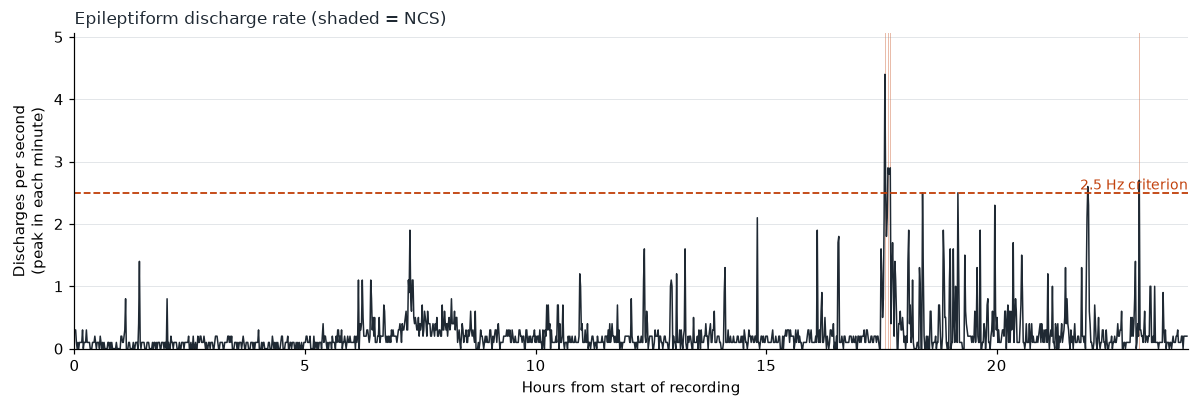

In [35]:
ink, accent, grey = "#1f2933", "#c2410c", "#8a94a0"          # dark text colour, highlight, grid

k = len(counts) // 60
rate = counts[: k * 60].reshape(k, 60).max(1) / RATE_WINDOW_S   # per-minute maximum, discharges per second

fig, ax = plt.subplots(figsize=(11, 3.8), dpi=110)
ax.plot((np.arange(k) * 60 + 30) / 3600, rate, color=ink, lw=1.0)
ax.axhline(ED_RATE_HZ, color=accent, lw=1.2, ls="--")
ax.text(total_s / 3600, ED_RATE_HZ, "  2.5 Hz criterion", color=accent, ha="right", va="bottom", fontsize=9)
for s in ncs:
    a = s["start_s"] / 3600
    ax.axvspan(a, max(s["end_s"] / 3600, a + 0.02), color=accent, alpha=0.35, lw=0)
ax.set_xlim(0, total_s / 3600)
ax.set_ylim(0, max(4.0, (rate.max() * 1.15) if len(rate) else 4.0))
ax.set_xlabel("Hours from start of recording")
ax.set_ylabel("Discharges per second\n(peak in each minute)")
ax.set_title("Epileptiform discharge rate (shaded = NCS)", loc="left", fontsize=11, color=ink)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.grid(axis="y", color=grey, alpha=0.25, lw=0.6)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "overview.png"))
plt.show()

## Step 17 - Look at the EEG itself (for expert review)
For each NCS (up to `MAX_EXCERPTS`) this draws **10 seconds of all leads** (in the montage you chose) starting at the beginning of the episode.
Orange vertical lines mark the discharges the detector counted. Check whether they are real epileptiform
discharges or something else (muscle, movement, ECG, electrode noise).

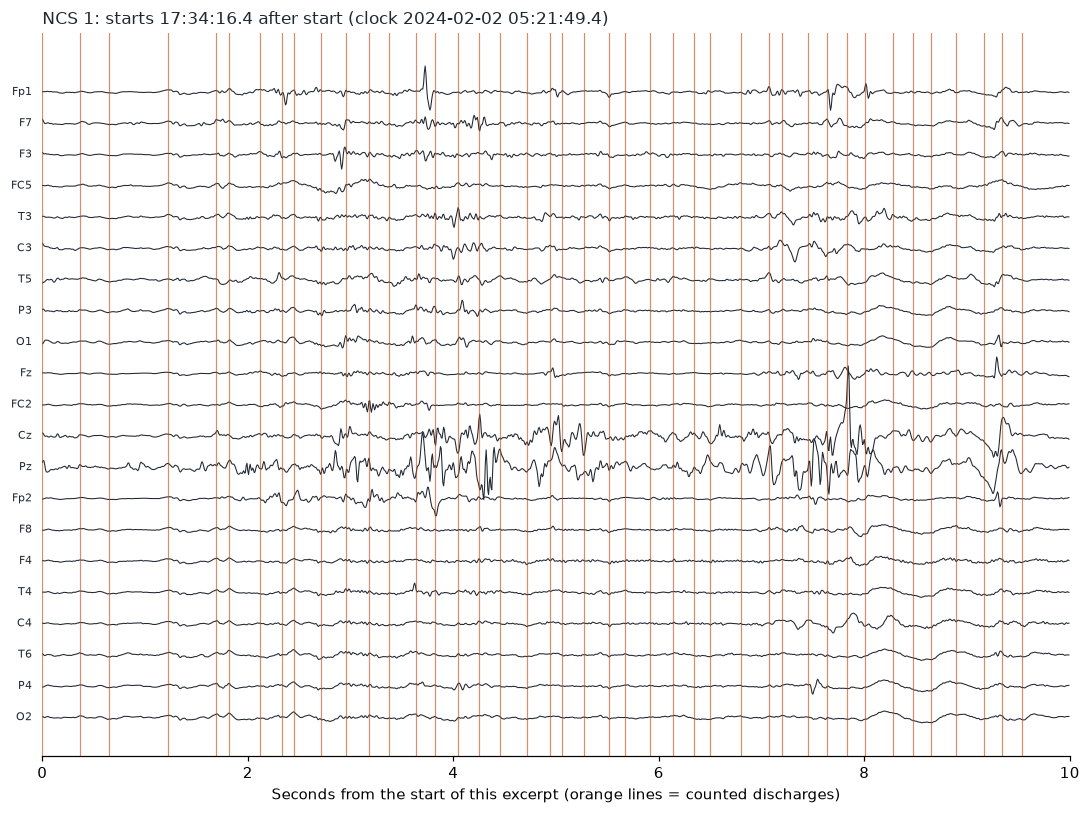

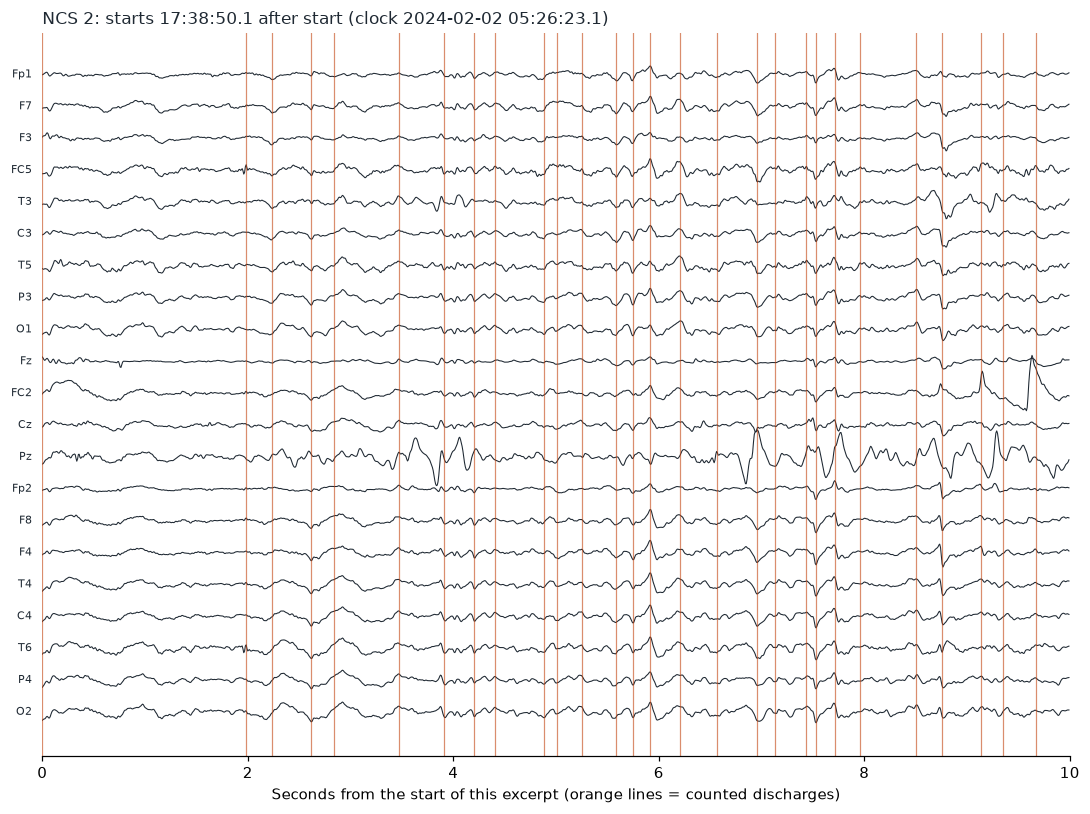

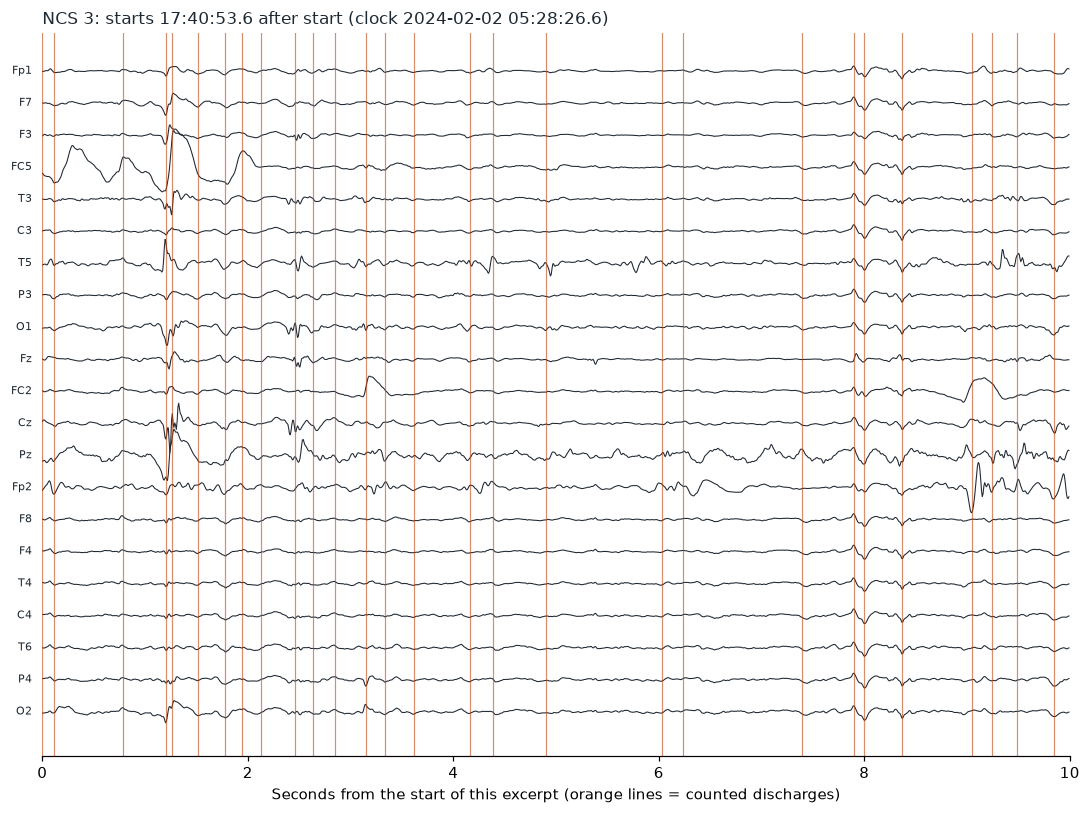

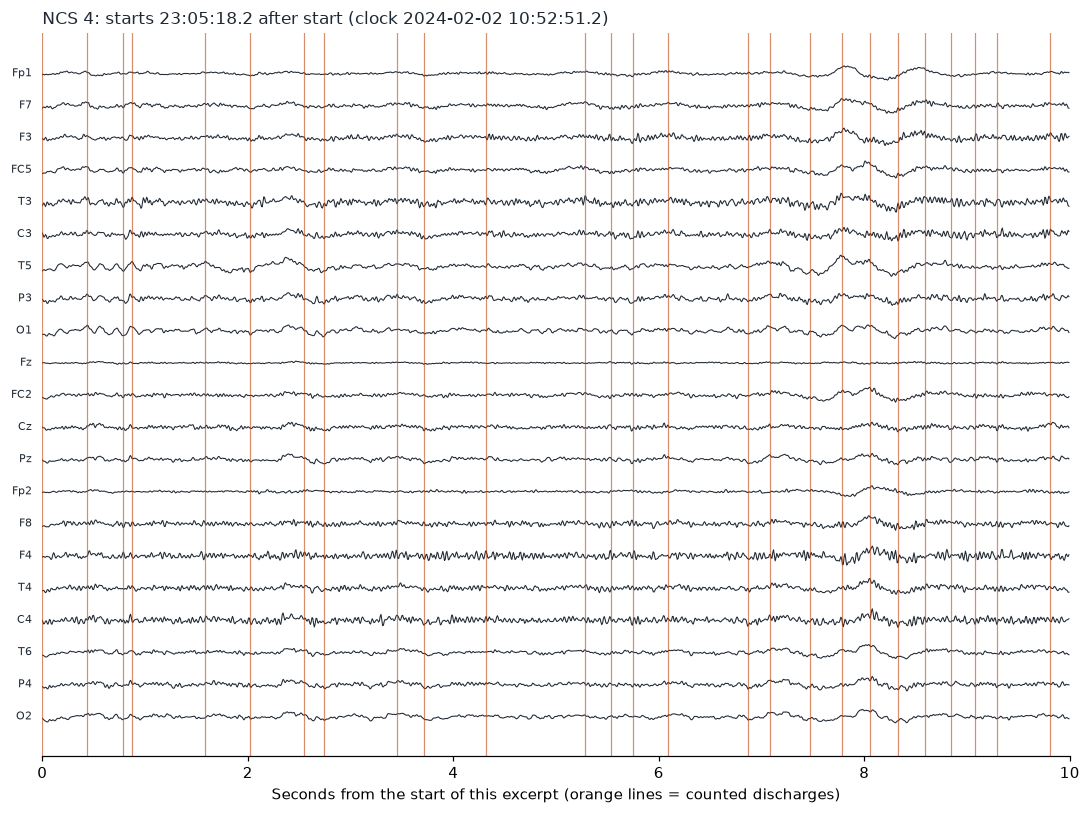

In [36]:
MAX_EXCERPTS = 5

def plot_excerpt(start_s, title, fname):
    r0 = max(min(start_s - 2, total_s - 14), 0.0)                 # a little context before the start
    r1 = min(r0 + 14, total_s)
    d, names = read_uv(r0, r1)
    labels, leads = build_leads(preprocess(d, fs), names, cal["bad"])
    i0 = int((start_s - r0) * fs)
    seg = leads[:, i0: i0 + int(RATE_WINDOW_S * fs)]              # exactly 10 s
    t = np.arange(seg.shape[1]) / fs                              # 0 ... 10 s
    step = max(200.0, 3 * np.percentile(np.abs(seg), 99))         # vertical spacing between leads

    fig, ax = plt.subplots(figsize=(10, 7.5), dpi=110)
    for j, lab in enumerate(labels):
        ax.plot(t, seg[j] - j * step, color=ink, lw=0.7)
        ax.text(-0.1, -j * step, lab, ha="right", va="center", fontsize=7, color=ink)
    for e in events[(events >= start_s) & (events < start_s + RATE_WINDOW_S)]:
        ax.axvline(e - start_s, color=accent, lw=0.8, alpha=0.6)  # detected discharges
    ax.set_yticks([]); ax.set_xlim(0, RATE_WINDOW_S)
    ax.set_xlabel("Seconds from the start of this excerpt (orange lines = counted discharges)")
    ax.set_title(title, loc="left", fontsize=11, color=ink)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, fname))
    plt.show()

for k, s in enumerate(ncs[:MAX_EXCERPTS], 1):
    plot_excerpt(s["start_s"], f"NCS {k}: starts {when(s['start_s'])}", f"excerpt_{k}.png")
if not ncs:
    print("No NCS found, so there are no excerpts to draw.")

## Notes, limits and how to tune
* **No seizure labels were available**, so the thresholds in Step 3 are untested defaults. If you get too many false detections, raise `MIN_PROM_UV` or `K_SIGMA`; if you miss obvious discharges, lower them. Always judge changes against an expert's markings.
* **Single-electrode focal discharges are rejected** on purpose (they look the same as a noisy electrode). Set `REQUIRE_MULTI_ELECTRODE = False` in Step 3 if those matter to you, and expect more false alarms.
* **Chunks marked "not evaluable"** had too few usable leads; the result says nothing about those periods.
* **Only the EEG-only branch** of the modified Salzburg criteria is implemented. Slower patterns (ED at or below 2.5 Hz, or rhythmic delta/theta) need the secondary criteria (response to medication, subtle clinical signs, evolution) and are **not** detected here.
* **Times match EDFbrowser.** "After start" is the time since the start of the recording (EDFbrowser's relative time display).
  "Clock" is the start time stored in the file header plus that time (EDFbrowser's real-time display); no time-zone conversion is applied.
  A discharge is timed at its sharpest peak, so look within about a second of the listed time in EDFbrowser.
* **To check a detection in EDFbrowser,** open the same EDF+ file, show the channels without a montage (unipolar, as recorded) and
  go to the listed time. Use the same band-pass (about 1-35 Hz) and the 50 Hz notch to compare like with like.
* This notebook is a screening aid. It does not replace review by a clinical neurophysiologist.